# CISA 5381 Group 3 Project
## Predicting High ROI Among U.S. College Graduates
CRISP-DM: Business Understanding, Data Understanding, Preparation, Modeling and Evaluation

**Research question:** Can we predict whether a graduate achieves high ROI using major, GPA, college cost, debt, region, and other available educational characteristics? How do high-ROI rates vary across U.S. regions?

**Target:** 'high_roi' (1 = top-quarter net ROI in this dataset; 0 = otherwise). This is a dataset-relative classification, not a universal ROI benchmark.

## 1. Data understanding

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

college = pd.read_csv('../data/college_major_roi.csv')
print('Shape:', college.shape)
college.head()

Shape: (30000, 18)


,grad_id,major,major_category,institution_tier,institution_selectivity_pctile,gpa,had_internship,completed_on_time,region,net_cost_usd,debt_usd,hs_baseline_10yr_usd,added_earnings_10yr_usd,earnings_10yr_usd,net_roi_usd,roi_pct,positive_roi,high_roi
0,G000000,biology,STEM,mid_tier,52,2.58,0,0,south,144400,0,411700,101000,512700,-43400,-30.0,0,0
1,G000001,marketing,business,mid_tier,61,2.58,0,1,northeast,57400,0,356900,330600,687500,273200,476.1,1,0
2,G000002,electrical_engineering,STEM,top_public,78,3.14,1,1,northeast,65100,39600,339600,655100,994700,590000,906.4,1,1
3,G000003,marketing,business,top_public,77,3.04,0,1,midwest,105800,81300,399600,197500,597100,91700,86.8,1,0
4,G000004,marketing,business,ivy_elite,100,3.81,0,0,south,219200,93500,335700,222900,558600,3800,1.7,1,0


In [2]:
# Check the dataset
college.info()
college.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   grad_id                         30000 non-null  object 
 1   major                           30000 non-null  object 
 2   major_category                  30000 non-null  object 
 3   institution_tier                30000 non-null  object 
 4   institution_selectivity_pctile  30000 non-null  int64  
 5   gpa                             30000 non-null  float64
 6   had_internship                  30000 non-null  int64  
 7   completed_on_time               30000 non-null  int64  
 8   region                          30000 non-null  object 
 9   net_cost_usd                    30000 non-null  int64  
 10  debt_usd                        30000 non-null  int64  
 11  hs_baseline_10yr_usd            30000 non-null  int64  
 12  added_earnings_10yr_usd         

,institution_selectivity_pctile,gpa,had_internship,completed_on_time,net_cost_usd,debt_usd,hs_baseline_10yr_usd,added_earnings_10yr_usd,earnings_10yr_usd,net_roi_usd,roi_pct,positive_roi,high_roi
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,3.000000e+04,3.000000e+04,30000.000000,30000.000000,30000.00000
mean,55.086067,3.093337,0.436067,0.682367,88621.496667,38498.063333,359893.416667,3.554752e+05,7.153680e+05,2.668537e+05,346.153987,0.835167,0.25000
std,18.593708,0.439060,0.495904,0.465564,33576.903160,37801.748200,39923.943255,2.948109e+05,2.977847e+05,2.949958e+05,398.666879,0.371036,0.43302
min,16.000000,1.500000,0.000000,0.000000,28500.000000,0.000000,250000.000000,1.000000e+04,2.723000e+05,-3.052000e+05,-92.100000,0.000000,0.00000
25%,42.000000,2.790000,0.000000,0.000000,65500.000000,0.000000,333100.000000,1.179000e+05,4.835000e+05,3.280000e+04,39.700000,1.000000,0.00000
50%,55.000000,3.100000,0.000000,1.000000,81000.000000,38700.000000,359700.000000,2.836500e+05,6.458000e+05,1.981000e+05,230.900000,1.000000,0.00000
75%,68.000000,3.400000,1.000000,1.000000,103600.000000,62300.000000,387300.000000,5.093000e+05,8.717000e+05,4.235250e+05,537.400000,1.000000,0.25000
max,102.000000,4.000000,1.000000,1.000000,352900.000000,331700.000000,480000.000000,2.894900e+06,3.245500e+06,2.755100e+06,3618.900000,1.000000,1.00000


The dataset contains **30,000 graduates and 18 columns**. The initial checks found no missing values or duplicate rows. 'institution_selectivity_pctile' contains 288 values above 100, which require an explicit cleaning decision.

In [3]:
# Check missing values
college.isnull().sum()

# Check duplicate records
college.duplicated().sum()

np.int64(0)

In [4]:
# Check the target distribution
college['high_roi'].value_counts()

# Check percentages
college['high_roi'].value_counts(normalize=True) * 100

high_roi
0    75.0
1    25.0
Name: proportion, dtype: float64

The classes are imbalanced. A model that predicts every graduate as not high ROI would achieve 75% accuracy. Therefore, accuracy alone is insufficient to judge our models.

In [5]:
# Check selectivity values above 100
college[college['institution_selectivity_pctile'] > 100]['institution_selectivity_pctile'].value_counts()

institution_selectivity_pctile
101    158
102    130
Name: count, dtype: int64

## 2. Data preparation and target definition

In [6]:
# Make a copy of the dataset
college_clean = college.copy()

# Limit selectivity percentiles to 100
college_clean['institution_selectivity_pctile'] = college_clean['institution_selectivity_pctile'].clip(upper=100)

In [7]:
# Check the target variable
print(college_clean.groupby('high_roi')['net_roi_usd'].agg(['min', 'max', 'mean', 'median']))

print('75th percentile of net ROI:', college_clean['net_roi_usd'].quantile(0.75))

             min      max           mean    median
high_roi                                          
0        -305200   423500  130235.711111  100800.0
1         423600  2755100  676707.733333  602300.0
75th percentile of net ROI: 423525.0


Target Check: The 75th percentile of net ROI is $423,525. The results suggest that 'high-roi' identifies graduates in the top 25% of net ROI. We also capped 288 selectivity percentile values above 100 at 100 because percentiles cannot exceed 100. This cleaning decision is an assumption that should be verified against the original data source.

## 3. Focused Exploratory Analysis

3.1 High ROI by Region

In [8]:
# Calculate the percentage of high ROI graduates by region
region_roi = college_clean.groupby('region')['high_roi'].mean() * 100

# Display the results
print(region_roi.round(2))

region
midwest      25.73
northeast    24.95
south        24.21
west         25.48
Name: high_roi, dtype: float64


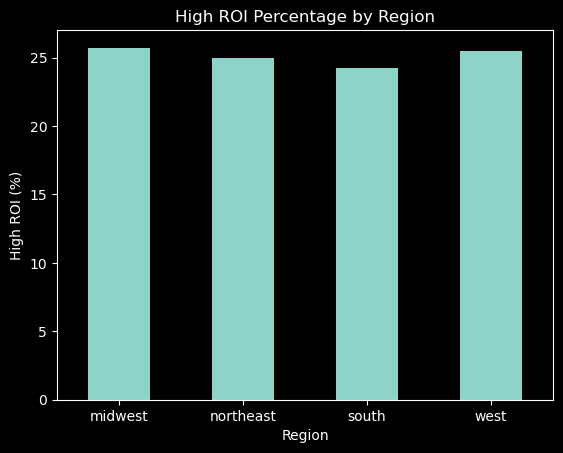

In [9]:
# Plot high ROI percentage by region
region_roi.plot(kind='bar')

plt.title('High ROI Percentage by Region')
plt.xlabel('Region')
plt.ylabel('High ROI (%)')
plt.xticks(rotation=0)
plt.show()

Regional Analysis: The Midwest has the highest percentage of graduates with high ROI (25.73%), while the South has the lowest (24.21%). The difference is only about 1.52 percentage points, suggesting that high-ROI rates vary relatively little across the four U.S. regions in this dataset.

In [10]:
# Calculate high ROI percentage by college major
major_roi = college_clean.groupby('major')['high_roi'].mean() * 100

# Display results from highest to lowest
print(major_roi.sort_values(ascending=False).round(2))

major
electrical_engineering    66.32
business_analytics        58.61
chemical_engineering      57.20
computer_science          56.33
computer_engineering      53.71
economics                 44.68
mechanical_engineering    41.47
nursing                   30.96
finance                   28.70
business                  15.88
biology                    1.73
marketing                  1.59
communications             0.17
psychology                 0.00
education                  0.00
humanities                 0.00
fine_arts                  0.00
criminal_justice           0.00
social_work                0.00
Name: high_roi, dtype: float64


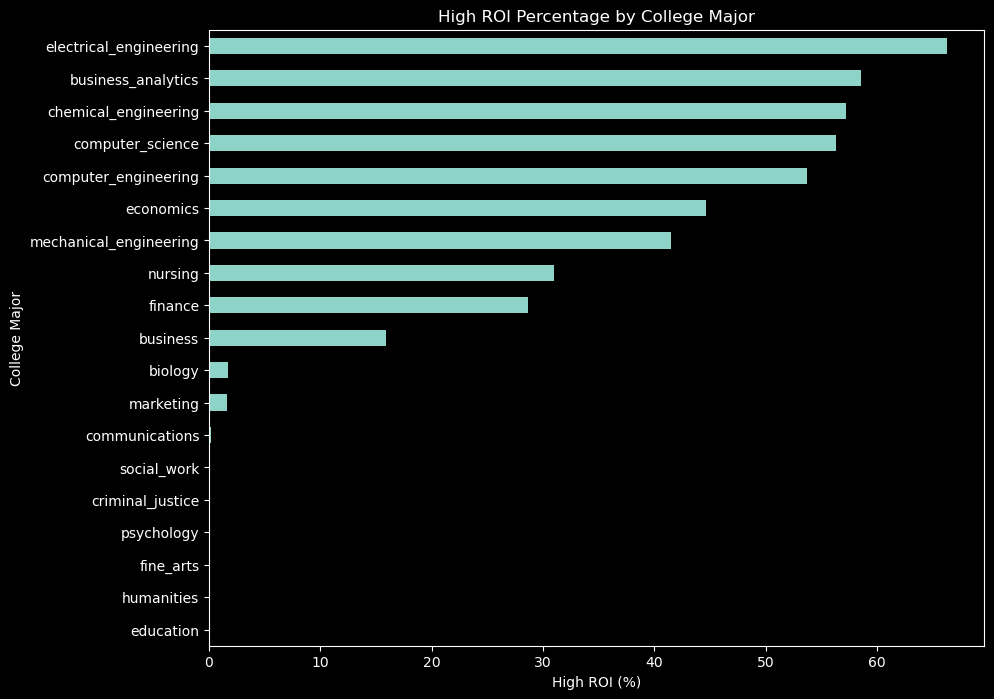

In [11]:
# Plot high ROI percentage by college major
major_roi.sort_values().plot(kind='barh', figsize=(10, 8))

plt.title('High ROI Percentage by College Major')
plt.xlabel('High ROI (%)')
plt.ylabel('College Major')
plt.show()

College Major Analysis: Electrical Engineering has the highest high-ROI rate at 66.32%, followed by Business Analytics (58.61%) and Chemical Engineering (57.20%). These results show substantial differences in high-ROI rates across college majors. Major appears to be an important factor associated with high ROI, although this analysis does not establish causation.

In [12]:
# Compare average GPA, college cost, and student debt
college_clean.groupby('high_roi')[['gpa', 'net_cost_usd', 'debt_usd']].mean().round(2)

,gpa,net_cost_usd,debt_usd
high_roi,,,
0,3.09,89228.28,38707.27
1,3.11,86801.13,37870.45


GPA, College Cost, and Debt Analysis: Graduates with high ROI have a slightly higher average GPA (3.11 compared with 3.09). They also have lower average college costs ($86,801 compared with $89,228) and student debt ($37,870 compared with $38,707). These differences suggest that academic performance and educational expenses may be associated with high ROI, although the differences are relatively small.

In [13]:
# STEP 3.6 - Internship experience and on-time graduation

# High ROI percentage by internship experience
print('High ROI by Internship:')
print((college_clean.groupby('had_internship')['high_roi'].mean() * 100).round(2))

# High ROI percentage by on-time graduation
print('\nHigh ROI by On-Time Graduation:')
print((college_clean.groupby('completed_on_time')['high_roi'].mean() * 100).round(2))

High ROI by Internship:
had_internship
0    20.12
1    31.31
Name: high_roi, dtype: float64

High ROI by On-Time Graduation:
completed_on_time
0    20.55
1    27.07
Name: high_roi, dtype: float64


Internship and Graduation Analysis: Graduates who completed internships had a higher high-ROI rate (31.31%) than those without internships (20.12%). Similarly, graduates who completed college on time had a higher high-ROI rate (27.07%) than those who did not (20.55%). These results suggest that internship experience and timely graduation are associated with higher ROI, but they do not establish causation.

In [14]:
# STEP 3.7 - High ROI by institution tier

tier_roi = college_clean.groupby('institution_tier')['high_roi'].mean() * 100

print(tier_roi.sort_values(ascending=False).round(2))

institution_tier
ivy_elite     38.47
top_public    32.89
mid_tier      26.78
regional      21.51
for_profit     5.39
Name: high_roi, dtype: float64


Institution Tier Analysis: Graduates from Ivy/Elite institutions have the highest high-ROI rate (38.47%), followed by Top Public institutions (32.89%). For-Profit institutions have the lowest rate (5.39%). These results show considerable differences across institution tiers, suggesting that institution type may be associated with high ROI. However, these differences do not establish that institution tier directly causes higher returns.

## 4. Model Preparation

4.1 Select Predictors and Target Variable

In [15]:
# Select the target variable
target = college_clean['high_roi']

# Remove columns that should not be used as predictors
features = college_clean.drop(columns=[
    'grad_id',
    'high_roi',
    'positive_roi',
    'net_roi_usd',
    'roi_pct',
    'earnings_10yr_usd',
    'added_earnings_10yr_usd',
    'hs_baseline_10yr_usd'
])

# Check the number of rows and predictors
print(features.shape)
print(target.shape)
print(features.columns)

(30000, 10)
(30000,)
Index(['major', 'major_category', 'institution_tier',
       'institution_selectivity_pctile', 'gpa', 'had_internship',
       'completed_on_time', 'region', 'net_cost_usd', 'debt_usd'],
      dtype='object')


Predictor Selection: We selected 10 predictors, including college major, institution tier, GPA, internship experience, graduation status, region, college cost, and student debt. We excluded the graduate ID because it is an identifier. We also excluded ROI and earnings-related variables because they could reveal information used to define the target variable ('high_roi'), creating data leakage and making the models appear more accurate than they would be in a real prediction setting.

In [16]:
# Convert categorical variables into numerical variables
features = pd.get_dummies(features, dtype=int)

# Check the new dimensions
print(features.shape)

(30000, 41)


In [17]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

train_features, test_features, train_target, test_target = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

# Check the dimensions
print(train_features.shape)
print(test_features.shape)

# Check the target distribution
print(train_target.value_counts())
print(test_target.value_counts())

(24000, 41)
(6000, 41)
high_roi
0    18000
1     6000
Name: count, dtype: int64
high_roi
0    4500
1    1500
Name: count, dtype: int64


Model Preparation: The dataset was divided into 80% training data and 20% testing data. Stratified sampling was used to preserve the proportion of high-ROI and non-high-ROI graduates in both subsets. The training data will be used to build the classification models, while the testing data will be reserved for evaluating their performance.

## 5. Decision Tree Classification
5.1 Decision Tree Model Selection

A maximum depth of 4 was selected based on earlier five-fold cross-validation results, where it achieved the highest average F1-score among the evaluated depths.

In [18]:
# Five-fold cross-validation for Decision Tree
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

for depth in [2, 3, 4, 5, 6, 8, 10]:
    dt_cv = DecisionTreeClassifier(max_depth=depth, random_state=42)

    scores = cross_val_score(
        dt_cv, train_features, train_target,
        cv=5, scoring='f1'
    )

    print('Depth:', depth, 'Mean F1-score:', round(scores.mean(), 4))

Depth: 2 Mean F1-score: 0.6306
Depth: 3 Mean F1-score: 0.6519
Depth: 4 Mean F1-score: 0.6596
Depth: 5 Mean F1-score: 0.6551
Depth: 6 Mean F1-score: 0.6338
Depth: 8 Mean F1-score: 0.637
Depth: 10 Mean F1-score: 0.6176


Five-fold cross-validation was conducted on the training data to evaluate different maximum depths for the Decision Tree classifier. A maximum depth of 4 achieved the highest average F1-score (0.6596) among the evaluated settings and was selected for the final model.

5.2 Train the Decision Tree Model

In [19]:
# Import the Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)

# Train the model
dt_model.fit(train_features, train_target)

# Make predictions
dt_predictions = dt_model.predict(test_features)

5.3 Evaluate the Decision Tree Model

In [20]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Evaluate the Decision Tree
print('Accuracy:', accuracy_score(test_target, dt_predictions))

print('Confusion Matrix:')
print(confusion_matrix(test_target, dt_predictions))

print('Classification Report:')
print(classification_report(test_target, dt_predictions))

Accuracy: 0.8175
Confusion Matrix:
[[3845  655]
 [ 440 1060]]
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.85      0.88      4500
           1       0.62      0.71      0.66      1500

    accuracy                           0.82      6000
   macro avg       0.76      0.78      0.77      6000
weighted avg       0.83      0.82      0.82      6000



Decision Tree Model Evaluation: The Decision Tree achieved an accuracy of 81.75%, exceeding the majority-class baseline accuracy of 75%. For the high-ROI class, the model achieved precision of 61.81%, recall of 70.67%, and an F1-score of 65.93%. The confusion matrix shows that the model correctly identified 1,060 high-ROI graduates but incorrectly classified 440 high-ROI graduates as not high ROI. These results indicate that the model can identify many high-ROI graduates, although some classification errors remain.

## 6. K-Nearest Neighbors Classification

6.1 Standardize the Predictor Variables

In [21]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
stdsc = StandardScaler()

# Standardize the training and testing features
train_features_std = stdsc.fit_transform(train_features)
test_features_std = stdsc.transform(test_features)

6.2 KNN Model Selection

Five-fold cross-validation was used to compare different values of K using the F1-score for the high-ROI class. Among the tested values, K = 21 achieved the highest average F1-score and was selected for the final KNN model.

In [22]:
# Five-fold cross-validation for KNN
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

for k in [3, 5, 7, 9, 11, 13, 15, 21]:
    knn_cv = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        knn_cv, train_features, train_target,
        cv=5, scoring='f1'
    )

    print('Neighbors:', k, 'Mean F1-score:', round(scores.mean(), 4))

Neighbors: 3 Mean F1-score: 0.5956
Neighbors: 5 Mean F1-score: 0.6091
Neighbors: 7 Mean F1-score: 0.6227
Neighbors: 9 Mean F1-score: 0.6268
Neighbors: 11 Mean F1-score: 0.631
Neighbors: 13 Mean F1-score: 0.634
Neighbors: 15 Mean F1-score: 0.6384
Neighbors: 21 Mean F1-score: 0.6467


 6.3 Train the KNN Model

In [23]:
# Import KNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=21)

# Train the model
knn_model.fit(train_features_std, train_target)

# Make predictions
knn_predictions = knn_model.predict(test_features_std)

6.4 Evaluate the KNN Model

In [24]:
# Evaluate the KNN model
print('Accuracy:', accuracy_score(test_target, knn_predictions))

print('Confusion Matrix:')
print(confusion_matrix(test_target, knn_predictions))

print('Classification Report:')
print(classification_report(test_target, knn_predictions))

Accuracy: 0.824
Confusion Matrix:
[[3947  553]
 [ 503  997]]
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.88      4500
           1       0.64      0.66      0.65      1500

    accuracy                           0.82      6000
   macro avg       0.77      0.77      0.77      6000
weighted avg       0.83      0.82      0.82      6000



KNN Model Evaluation: The KNN model with 21 neighbors achieved an accuracy of 82.40%. For the high-ROI class (1), precision was approximately 64.32%, recall was 66.47%, and the F1-score was 65.38%. The confusion matrix shows that the model correctly classified 997 high-ROI graduates while incorrectly classifying 503 as low ROI. Although the model achieved good overall accuracy, it did not identify every high-ROI graduate.

## 7. Model Comparison

In [25]:
# Compare Decision Tree and KNN models
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    'Model': ['Decision Tree', 'KNN'],
    'Accuracy': [
        accuracy_score(test_target, dt_predictions),
        accuracy_score(test_target, knn_predictions)
    ],
    'Precision': [
        precision_score(test_target, dt_predictions),
        precision_score(test_target, knn_predictions)
    ],
    'Recall': [
        recall_score(test_target, dt_predictions),
        recall_score(test_target, knn_predictions)
    ],
    'F1 Score': [
        f1_score(test_target, dt_predictions),
        f1_score(test_target, knn_predictions)
    ]
})

print(results.round(4))

           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.8175     0.6181  0.7067    0.6594
1            KNN    0.8240     0.6432  0.6647    0.6538


Model Comparison: Both classification models achieved accuracy above the 75% majority-class baseline. KNN achieved higher overall accuracy (82.40%) than Decision Tree (81.75%) and higher precision for the high-ROI class (64.32% versus 61.81%). However, Decision Tree achieved higher recall (70.67% versus 66.47%) and a slightly higher F1-score (65.94% versus 65.38%), making it more effective at identifying high-ROI graduates.

Selected Model: Decision Tree was selected as the preferred model because the main objective is to identify graduates with high ROI. Its higher recall means it identifies more actual high-ROI graduates, while its slightly higher F1-score provides a better balance between precision and recall for this class. Although KNN achieved higher overall accuracy, Decision Tree better supports the project's primary objective.

## 8. Final Findings and Conclusion

8.1 Research Questions and Findings

**Research Question 1: Can classification models accurately predict whether a college graduate achieves high ROI?**

Yes. Both models achieved accuracy above the 75% majority-class baseline. Decision Tree achieved 81.75% accuracy, while KNN achieved 82.40%. However, neither model correctly identified every high-ROI graduate.

**Research Question 2: Which factors are most useful in predicting high ROI?**

The exploratory analysis showed substantial differences in high-ROI rates across college majors and institution tiers. Electrical Engineering had the highest high-ROI rate (66.32%), while Ivy/Elite institutions had the highest rate among institution tiers (38.47%). Internship experience and on-time graduation were also associated with higher high-ROI rates.

These are descriptive associations. Identifying the most influential predictors within the trained model would require a separate feature-importance analysis.

**Research Question 3: How does high ROI vary across U.S. regions?**

The Midwest had the highest high-ROI rate (25.73%), followed by the West (25.48%), Northeast (24.95%), and South (24.21%). The difference between the highest and lowest regions was approximately 1.52 percentage points, indicating relatively small regional differences in this dataset.

**Research Question 4: Which classification technique performs better?**

KNN achieved higher overall accuracy (82.40%) than Decision Tree (81.75%) and higher precision for the high-ROI class (64.32% versus 61.81%). However, Decision Tree achieved higher recall (70.67% versus 66.47%) and a slightly higher F1-score (65.94% versus 65.38%). Therefore, Decision Tree was selected as the preferred model because identifying high-ROI graduates is the primary objective.

8.2 Conclusion

This project applied the CRISP-DM framework to analyze 30,000 college graduate records and predict high return on investment using Decision Tree and K-Nearest Neighbors classification models.

Both models performed better than the majority-class baseline, demonstrating that the selected predictors contain useful information for classifying high ROI. College major and institution tier showed notable differences in high-ROI rates, while internship participation and on-time graduation were also associated with higher rates.

Although KNN achieved slightly higher overall accuracy, Decision Tree provided better recall and F1-score for the high-ROI class and was selected as the preferred model.

The findings demonstrate how classification techniques can support the analysis of educational outcomes. However, the results show associations rather than causal relationships, and further validation would be needed before using the model for real-world decisions.

8.3 Limitations

The dataset contains 30,000 graduate records, but the findings may not represent all U.S. college graduates. Since only 25% of graduates belong to the high-ROI class, accuracy alone is not sufficient to evaluate model performance.

The analysis identifies associations between graduate characteristics and ROI but does not establish causation. Further testing with additional data would be necessary before using the models for real-world decisions.